# Cancer Prediction – Stacking Classifier (continuation)
**Stacking:** several *base models* make predictions, and a trained **meta-classifier** (Level 2) learns how to combine those predictions into the final answer.

```
Base models (Level 1)  ->  predictions become input features  ->  Meta-Classifier (Level 2)  ->  Final prediction
```

**Tasks**
1. Select the top three models from the previous task
2. Train and create the stacking model
3. Test and predict with user input data (Test 1 and Test 2)

> Set `CSV_PATH` in the first code cell if the file is not next to this notebook.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, StackingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)

%matplotlib inline
sns.set_theme(style="whitegrid")

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Recap of the previous activity (same preprocessing, same split, same 7 models)

In [3]:
CSV_PATH = "/content/drive/MyDrive/Could_Ml_classwork/03. ML Class Activity /Cancer_Predict.csv"
df = pd.read_csv(CSV_PATH).astype("float64")

TARGET = "Diagnosis"
FEATURES = [c for c in df.columns if c != TARGET]

# Outliers (IQR clipping on continuous columns - none were found previously)
for c in ["Age", "BMI", "PhysicalActivity", "AlcoholIntake"]:
    q1, q3 = df[c].quantile([0.25, 0.75]); iqr = q3 - q1
    df[c] = df[c].clip(q1 - 1.5 * iqr, q3 + 1.5 * iqr)

X, y = df[FEATURES], df[TARGET].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)
print("Train:", X_train_s.shape, "| Test:", X_test_s.shape)

Train: (1200, 8) | Test: (300, 8)


In [4]:
models = {
    "Logistic Regression": LogisticRegression(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "SVM": SVC(probability=True, random_state=42),
    "KNN": KNeighborsClassifier(),
    "Naive Bayes": GaussianNB(),
}

rows = []
for name, m in models.items():
    m.fit(X_train_s, y_train)
    p = m.predict(X_test_s)
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, p),
                 "Precision": precision_score(y_test, p),
                 "Recall": recall_score(y_test, p),
                 "F1-score": f1_score(y_test, p)})
results = pd.DataFrame(rows).sort_values("F1-score", ascending=False).reset_index(drop=True)
results.round(4)

,Model,Accuracy,Precision,Recall,F1-score
0,Gradient Boosting,0.9467,0.9439,0.9099,0.9266
1,Random Forest,0.9400,0.9515,0.8829,0.9159
2,KNN,0.9100,0.9200,0.8288,0.8720
3,SVM,0.8933,0.8911,0.8108,0.8491
4,Decision Tree,0.8667,0.7983,0.8559,0.8261
5,Logistic Regression,0.8433,0.7963,0.7748,0.7854
6,Naive Bayes,0.8300,0.8659,0.6396,0.7358


## Task 1: Select the top three models from the previous task
Models are ranked by **F1-score** (same criterion used to pick the best model last time).

In [5]:
top3_names = results["Model"].head(3).tolist()
print("Top 3 models:", top3_names)
results.head(3).round(4)

Top 3 models: ['Gradient Boosting', 'Random Forest', 'KNN']


,Model,Accuracy,Precision,Recall,F1-score
0,Gradient Boosting,0.9467,0.9439,0.9099,0.9266
1,Random Forest,0.9400,0.9515,0.8829,0.9159
2,KNN,0.9100,0.9200,0.8288,0.8720


## Task 2: Train and create the Stacking model
- **Level 1 (base models):** the top three models above.
- **Level 2 (meta-classifier):** `LogisticRegression` – a simple, stable model that learns how much to trust each base model.
- `cv=5`: the meta-classifier is trained on *out-of-fold* predictions of the base models, so it does not learn from predictions the base models made on data they had already seen (this prevents overfitting).
- `stack_method="predict_proba"`: the base models pass their probabilities to the meta-classifier.

In [6]:
base_models = [(name, models[name]) for name in top3_names]

stack = StackingClassifier(
    estimators=base_models,
    final_estimator=LogisticRegression(),
    cv=5,
    stack_method="predict_proba",
)
stack.fit(X_train_s, y_train)
print("Stacking classifier trained.\n")
print("Level 1 base models :", [n for n, _ in base_models])
print("Level 2 meta-model  :", stack.final_estimator_)

Stacking classifier trained.

Level 1 base models : ['Gradient Boosting', 'Random Forest', 'KNN']
Level 2 meta-model  : LogisticRegression()


In [7]:
# SCREENSHOT: how the meta-classifier combines the base models
coef = pd.DataFrame({
    "Base model": top3_names,
    "Meta-classifier weight": stack.final_estimator_.coef_[0].round(4)})
print("Meta-classifier intercept:", stack.final_estimator_.intercept_.round(4))
coef

Meta-classifier intercept: [-3.7073]


,Base model,Meta-classifier weight
0,Gradient Boosting,4.5614
1,Random Forest,2.3738
2,KNN,0.7554


In [8]:
# Performance of the stacking model on the test set vs. the base models
sp = stack.predict(X_test_s)
stack_row = {"Model": "Stacking (Meta: Logistic Regression)",
             "Accuracy": accuracy_score(y_test, sp),
             "Precision": precision_score(y_test, sp),
             "Recall": recall_score(y_test, sp),
             "F1-score": f1_score(y_test, sp)}
compare = pd.concat([results.head(3), pd.DataFrame([stack_row])], ignore_index=True)
compare.round(4)

,Model,Accuracy,Precision,Recall,F1-score
0,Gradient Boosting,0.9467,0.9439,0.9099,0.9266
1,Random Forest,0.9400,0.9515,0.8829,0.9159
2,KNN,0.9100,0.9200,0.8288,0.8720
3,Stacking (Meta: Logistic Regression),0.9467,0.9524,0.9009,0.9259


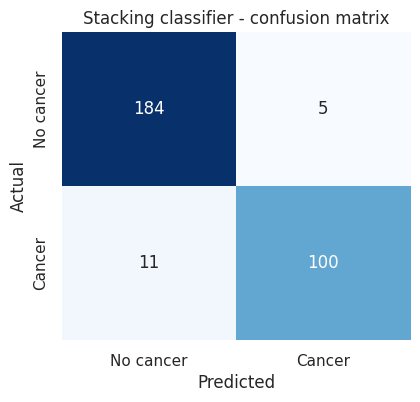

[[TN, FP], [FN, TP]] = [[184, 5], [11, 100]]


In [9]:
cm = confusion_matrix(y_test, sp)
plt.figure(figsize=(4.5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["No cancer", "Cancer"], yticklabels=["No cancer", "Cancer"])
plt.title("Stacking classifier - confusion matrix")
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.show()
print("[[TN, FP], [FN, TP]] =", cm.tolist())

## Task 3: Test and predict with user input data
Each input is wrapped in a DataFrame with the same column order, **scaled with the same scaler** fitted on the training data, then passed to the stacking model. We show what each base model predicts (Level 1) and what the meta-classifier decides (Level 2).

In [10]:
test_inputs = {
    "Test 1": {"Age": 28, "Gender": 0, "BMI": 22.5, "Smoking": 0, "GeneticRisk": 0,
               "PhysicalActivity": 8.0, "AlcoholIntake": 0.5, "CancerHistory": 0},
    "Test 2": {"Age": 72, "Gender": 1, "BMI": 34.5, "Smoking": 1, "GeneticRisk": 2,
               "PhysicalActivity": 1.5, "AlcoholIntake": 4.5, "CancerHistory": 1},
}
label = {0: "No Cancer (Benign)", 1: "Cancer (Malignant)"}

summary = []
for test_name, values in test_inputs.items():
    row = pd.DataFrame([values])[FEATURES].astype("float64")
    row_s = scaler.transform(row)

    print("=" * 60)
    print(test_name)
    print(row.T.rename(columns={0: "Value"}).to_string())
    print("\nLevel 1 - base model predictions:")
    for name, est in zip(top3_names, stack.estimators_):
        pred = int(est.predict(row_s)[0])
        prob = est.predict_proba(row_s)[0, 1]
        print(f"  {name:<18} -> {label[pred]:<20} (P(cancer) = {prob:.3f})")

    final = int(stack.predict(row_s)[0])
    p_final = stack.predict_proba(row_s)[0, 1]
    print(f"\nLevel 2 - Meta-classifier FINAL PREDICTION: {label[final]}  (P(cancer) = {p_final:.3f})")
    summary.append({"Test": test_name, "Final prediction": label[final],
                    "P(cancer)": round(p_final, 3)})

print("=" * 60)
pd.DataFrame(summary)

Test 1
                  Value
Age                28.0
Gender              0.0
BMI                22.5
Smoking             0.0
GeneticRisk         0.0
PhysicalActivity    8.0
AlcoholIntake       0.5
CancerHistory       0.0

Level 1 - base model predictions:
  Gradient Boosting  -> No Cancer (Benign)   (P(cancer) = 0.010)
  Random Forest      -> No Cancer (Benign)   (P(cancer) = 0.010)
  KNN                -> No Cancer (Benign)   (P(cancer) = 0.000)

Level 2 - Meta-classifier FINAL PREDICTION: No Cancer (Benign)  (P(cancer) = 0.026)
Test 2
                  Value
Age                72.0
Gender              1.0
BMI                34.5
Smoking             1.0
GeneticRisk         2.0
PhysicalActivity    1.5
AlcoholIntake       4.5
CancerHistory       1.0

Level 1 - base model predictions:
  Gradient Boosting  -> Cancer (Malignant)   (P(cancer) = 1.000)
  Random Forest      -> Cancer (Malignant)   (P(cancer) = 0.970)
  KNN                -> Cancer (Malignant)   (P(cancer) = 0.800)

Level 2 

,Test,Final prediction,P(cancer)
0,Test 1,No Cancer (Benign),0.026
1,Test 2,Cancer (Malignant),0.977


## Conclusion
- **Stacking** combines the top three models (Gradient Boosting, Random Forest, KNN) through a trained meta-classifier rather than a simple vote, so the meta-classifier learns which base model deserves more weight.
- The table in Task 2 compares the stacking model with its three base models on the same test set.
- **Test 1** (young, low BMI, non-smoker, active, no genetic risk or history) and **Test 2** (older, high BMI, smoker, high genetic risk, inactive, cancer history) represent a low-risk and a high-risk patient; the Task 3 output shows each base model's opinion and the final decision.
- *Note: this is a classroom model on a small dataset, not a medical diagnostic tool.*